# Partie 2 — Régression Logistique vs SVM
**Mini-projet Machine Learning : prédiction du décrochage scolaire et de la réussite académique**
Jeu de données : UCI n°697, *Predict Students' Dropout and Academic Success* (4 424 étudiants, 36 variables, 3 classes : `Dropout`, `Enrolled`, `Graduate`) [1].

Ce notebook (`P2/`) couvre la **tâche 2** : comparer une Régression Logistique multiclasse et un SVM sur les variables sélectionnées par l'arbre de décision de P1 (k = 4), avec **F1-score, matrices de confusion et courbes ROC**.

### Scénario de prédiction
Prédiction **en fin de 2ᵉ semestre** (les variables de performance des semestres 1 et 2 sont disponibles). Ce modèle n'est donc **pas** un outil d'alerte dès l'inscription ; une expérience complémentaire (§ 9) mesure ce qui se passe sans les variables de performance.

### Règles d'équipe respectées
Graine unique 42 · découpage `data_split/` fourni par P1 (jamais redécoupé) · test utilisé **une seule fois par modèle** · tout ce qui s'apprend (normalisation, catégories rares, hyperparamètres) s'apprend sur le **train seulement** · classes ordonnées `Dropout, Enrolled, Graduate` · jugement sur le **F1 macro** et les résultats par classe.

### Contribution personnelle (ce qui est écrit « à la main » dans ce notebook)
| # | Élément personnalisé | Variante standard comparée | Référence |
|---|---|---|---|
| 1 | Régression logistique softmax en NumPy : gradient exact vérifié numériquement, régularisation L2, **pondération des classes**, optimiseur **Adam**, **arrêt précoce** | `sklearn.LogisticRegression` | [6][7][8][11][16] |
| 2 | SVM linéaire One-vs-Rest par **Pegasos** (sous-gradient stochastique mini-batch) avec **poids de classes**, **moyennage d'itérés** et option **hinge au carré** | `LinearSVC` | [3][4][12][17] |
| 3 | SVM **non linéaire** = **Random Fourier Features** + notre SVM linéaire (approximation du noyau RBF) | `SVC(kernel="rbf")` | [5] |
| 4 | Métriques F1 (macro / weighted / par classe), matrice de confusion, **courbes ROC One-vs-Rest et AUC** codées à la main, vérifiées contre scikit-learn | `sklearn.metrics` | [9][10] |
| 5 | Validation croisée stratifiée où le **préprocesseur est ré-appris dans chaque pli** (pas de fuite des statistiques de prétraitement) | CV avec scaler appris une fois | [15] |
| 6 | **Intervalles de confiance bootstrap** sur le F1 macro et différences appariées entre modèles | Comparaison de scores bruts | [13] |
| 7 | **Ablation** : 4 variables vs sans `Course` vs toutes vs « sans performances académiques » | — | [1][2] |

> scikit-learn est utilisé pour le **prétraitement**, les **modèles de référence**, le découpage des plis et la **vérification** de nos implémentations. Les numéros `[n]` renvoient à la bibliographie en fin de notebook.

## 1. Importation des bibliothèques
On fixe aussi la graine **42** (règle d'équipe) et l'ordre des classes. scikit-learn sert au prétraitement et aux modèles de référence ; nos propres implémentations et les fonctions de vérification sont définies plus bas.

In [23]:
import json, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import f1_score, roc_auc_score          # uniquement pour VÉRIFIER nos fonctions
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
np.random.seed(SEED)
CLASSES = ["Dropout", "Enrolled", "Graduate"]   # ordre imposé par l'équipe
K = len(CLASSES)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

## 2. Chargement des données déjà découpées par P1
On lit `X_train`, `X_test`, `y_train`, `y_test`, `config.json` et `selected_features.json` dans `data_split/`. Le code détecte automatiquement le séparateur (virgule ou point-virgule) et les chemins (`../data_split` si le notebook est dans `P2/`). Les étiquettes texte sont converties en entiers **0/1/2** selon l'ordre `Dropout, Enrolled, Graduate`.

On vérifie aussi que les variables sélectionnées existent bien dans `X_train` et que la cible n'est pas dans `X`.

In [24]:
DATA_DIR = next(p for p in [Path("../data_split"), Path("data_split")] if p.exists())
FIG_DIR = Path("../figures") if Path("../figures").exists() else Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def read_csv_auto(path):
    first = open(path, encoding="utf-8-sig").readline()
    sep = ";" if first.count(";") > first.count(",") else ","      # détecte « , » ou « ; »
    df = pd.read_csv(path, sep=sep, encoding="utf-8-sig")
    return df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

X_train = read_csv_auto(DATA_DIR / "X_train.csv")
X_test  = read_csv_auto(DATA_DIR / "X_test.csv")
y_train_txt = read_csv_auto(DATA_DIR / "y_train.csv").iloc[:, 0].astype(str).str.strip()
y_test_txt  = read_csv_auto(DATA_DIR / "y_test.csv").iloc[:, 0].astype(str).str.strip()

config = json.load(open(DATA_DIR / "config.json", encoding="utf-8"))
sel = json.load(open(DATA_DIR / "selected_features.json", encoding="utf-8"))
if isinstance(sel, dict):                                        # accepte {"selected_features": [...]} etc.
    key = next((k for k in ("selected_features", "features") if k in sel), None)
    sel = sel[key] if key else next(v for v in sel.values() if isinstance(v, list))
FEATURES = list(sel)

to_int = {c: i for i, c in enumerate(CLASSES)}
y_train = y_train_txt.map(to_int).to_numpy()
y_test  = y_test_txt.map(to_int).to_numpy()
assert not np.isnan(y_train.astype(float)).any() and not np.isnan(y_test.astype(float)).any(), "étiquette inconnue"
assert all(f in X_train.columns for f in FEATURES), "variable sélectionnée absente de X_train"
assert "Target" not in X_train.columns, "la cible ne doit pas être dans X"

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Variables retenues par P1 :", FEATURES)
pd.DataFrame({"train": np.bincount(y_train, minlength=K), "test": np.bincount(y_test, minlength=K)},
             index=CLASSES).assign(train_pct=lambda d: (100*d.train/d.train.sum()).round(1))

Train : (3539, 36) | Test : (885, 36)
Variables retenues par P1 : ['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Course', 'Curricular units 1st sem (evaluations)']


,train,test,train_pct
Dropout,1137,284,32.1
Enrolled,635,159,17.9
Graduate,1767,442,49.9


**Lecture :** la répartition des classes n'est pas uniforme (`Graduate` domine, `Enrolled` est minoritaire). C'est la raison pour laquelle nous jugeons les modèles sur le **F1 macro** (moyenne non pondérée des F1 par classe) et non sur l'accuracy [10], et pour laquelle nous testons la **pondération des classes** [11].

## 3. Prétraitement (sans fuite des statistiques)
Deux règles : **(i)** tout paramètre est appris sur le train ; **(ii)** les variables codées par des nombres mais qui représentent des **catégories** (ex. `Course`, 17 modalités) sont encodées en **one-hot**, les modalités rares (< 20 observations dans le train) étant regroupées par `OneHotEncoder`.

- variables numériques continues → standardisation (moyenne/écart-type du **train**),
- variables binaires → 0/1 inchangées,
- variables catégorielles → one-hot.

La normalisation est indispensable pour le SVM (noyau et marge sensibles aux échelles) et utile à la descente de gradient de la régression logistique.

> **Cohérence d'équipe :** les variables viennent de `selected_features.json` et leurs types de `config.json` dans `data_split/`. `ColumnTransformer` applique `StandardScaler` aux variables numériques, le one-hot à `Course` et laisse les binaires inchangées. Il est ajusté uniquement sur le train, y compris dans chaque pli de validation croisée.

In [25]:
MIN_FREQUENCY = 20
binary_cols = config["binary_cols"]
nominal_cols = config["nominal_cols"]
numeric_cols = config["numeric_cols"]

def make_prep(features):
    num = [c for c in features if c in numeric_cols]
    nom = [c for c in features if c in nominal_cols]
    bi = [c for c in features if c in binary_cols]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=MIN_FREQUENCY, sparse_output=False), nom),
        ("bin", "passthrough", bi),
    ], remainder="drop", verbose_feature_names_out=False)

prep_demo = make_prep(FEATURES)
Xtr_demo = prep_demo.fit_transform(X_train[FEATURES])
print("Colonnes après encodage :", Xtr_demo.shape[1])
print(list(prep_demo.get_feature_names_out()))

Colonnes après encodage : 20
['Curricular units 2nd sem (approved)', 'Curricular units 1st sem (evaluations)', 'Course_171', 'Course_8014', 'Course_9003', 'Course_9070', 'Course_9085', 'Course_9119', 'Course_9130', 'Course_9147', 'Course_9238', 'Course_9254', 'Course_9500', 'Course_9556', 'Course_9670', 'Course_9773', 'Course_9853', 'Course_9991', 'Course_infrequent_sklearn', 'Tuition fees up to date']


**Attention :** `Course` à 17 modalités fournit la majorité des colonnes encodées. Avec une régularisation L2 ou un noyau RBF, ces colonnes pèsent beaucoup dans la distance / la pénalité ; c'est pourquoi l'**ablation** du § 9 mesure l'effet de cette variable.

## 4. Métriques d'évaluation écrites à la main
**Fonction personnalisée** — *Réf. [9] Fawcett (2006) pour ROC/AUC ; [10] Sokolova & Lapalme (2009) pour les mesures de performance multiclasses.*

- `confusion_matrix_np` : lignes = classe réelle, colonnes = classe prédite.
- `summarize` : précision, rappel et **F1 par classe** (`F1 = 2PR/(P+R)`), **F1 macro** (moyenne simple, sensible aux classes minoritaires), **F1 weighted** (pondérée par les effectifs), accuracy et accuracy équilibrée (= rappel macro).
- `roc_curve_np` / `auc_np` : courbe ROC **One-vs-Rest** (chaque classe contre les deux autres) obtenue en balayant tous les seuils de score ; AUC par la méthode des trapèzes. L'AUC macro est la moyenne des AUC par classe.

Le One-vs-Rest est choisi car il fournit une courbe par classe interprétable (par ex. « Dropout contre le reste ») et s'applique aussi bien à des probabilités (LogReg) qu'à des scores de marge (SVM).

In [26]:
def confusion_matrix_np(y_true, y_pred, k=K):
    cm = np.zeros((k, k), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def prf_from_cm(cm):
    tp = np.diag(cm).astype(float)
    precision = tp / np.maximum(cm.sum(axis=0), 1)
    recall    = tp / np.maximum(cm.sum(axis=1), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return precision, recall, f1, cm.sum(axis=1)

def f1_macro(y_true, y_pred):
    return prf_from_cm(confusion_matrix_np(y_true, y_pred))[2].mean()

def summarize(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    p, r, f1, sup = prf_from_cm(cm)
    out = {"accuracy": np.trace(cm) / cm.sum(), "balanced_acc": r.mean(),
           "f1_macro": f1.mean(), "f1_weighted": (f1 * sup).sum() / sup.sum()}
    out.update({f"f1_{c}": f for c, f in zip(CLASSES, f1)})
    return out

def roc_curve_np(y_bin, score):
    # Courbe ROC binaire : on trie les scores décroissants et on cumule vrais/faux positifs à chaque seuil distinct.
    order = np.argsort(-score, kind="mergesort")
    s, yb = score[order], y_bin[order]
    tps, fps = np.cumsum(yb), np.cumsum(1 - yb)
    idx = np.r_[np.where(np.diff(s))[0], len(s) - 1]          # un point par seuil distinct (gère les ex æquo)
    return np.r_[0, fps[idx] / fps[-1]], np.r_[0, tps[idx] / tps[-1]]

def auc_np(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))

def roc_ovr(y_true, scores):
    curves = {}
    for k, name in enumerate(CLASSES):
        fpr, tpr = roc_curve_np((y_true == k).astype(int), scores[:, k])
        curves[name] = (fpr, tpr, auc_np(fpr, tpr))
    return curves, float(np.mean([v[2] for v in curves.values()]))

**Test unitaire de nos métriques** (sur des données aléatoires) : on compare nos résultats à scikit-learn. Les écarts doivent être de l'ordre de 1e-12.

In [27]:
rng = np.random.default_rng(0)
yt = rng.integers(0, K, 500); yp = np.where(rng.random(500) < .6, yt, rng.integers(0, K, 500))
sc = rng.normal(size=(500, K)) + 1.5 * np.eye(K)[yt]
print("F1 macro    :", abs(f1_macro(yt, yp) - f1_score(yt, yp, average="macro")))
print("F1 weighted :", abs(summarize(yt, yp)["f1_weighted"] - f1_score(yt, yp, average="weighted")))
curves, macro_auc = roc_ovr(yt, sc)
print("AUC / classe:", [abs(curves[c][2] - roc_auc_score((yt == k).astype(int), sc[:, k])) for k, c in enumerate(CLASSES)])

F1 macro    : 2.220446049250313e-16
F1 weighted : 0.0
AUC / classe: [1.1102230246251565e-16, 1.1102230246251565e-16, 0.0]


## 5. Régression logistique softmax écrite à la main
**Fonction personnalisée** — *Réf. [7] Bishop (2006), § 4.3.4 (régression logistique multiclasse) ; [8] Hastie et al. (2009), chap. 4 ; [16] Hoerl & Kennard (1970) pour la pénalité L2 ; [6] Kingma & Ba (2015) pour Adam ; [11] Japkowicz & Stephen (2002) pour la pondération des classes face au déséquilibre.*

**Modèle** : `P(y=k|x) = softmax(xᵀW)_k`. **Perte minimisée** (moyenne pondérée) :
`L(W) = (1/Σwᵢ) Σᵢ wᵢ·(−log P(yᵢ|xᵢ)) + (λ/2)‖W‖²` (le biais n'est pas pénalisé), avec `wᵢ` = poids de la classe de l'exemple `i`. **Gradient exact** : `Xᵀ[(P − Y)·w]/Σw + λW`.

**Améliorations par rapport à la version standard** (testées au § 7.3) :
1. **Pondération `balanced`** : `w_k = n / (K·n_k)`, les erreurs sur `Enrolled` coûtent plus cher.
2. **Adam** (moments adaptatifs) à la place de la descente de gradient simple.
3. **Arrêt précoce** sur 10 % du train (stratifié) : limite le sur-apprentissage sans avoir à fixer le nombre d'époques.

Équivalence avec scikit-learn : `λ = 1/(C·n)` (ce qui permet de comparer notre `λ` au `C` de `LogisticRegression`).

In [28]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)           # stabilité numérique
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def balanced_weights(y, k=K):
    counts = np.bincount(y, minlength=k)
    return len(y) / (k * np.maximum(counts, 1))

def resolve_class_weight(class_weight, y):
    if class_weight is None:      return np.ones(K)
    if class_weight == "balanced": return balanced_weights(y)
    return np.asarray(class_weight, dtype=float)

class SoftmaxRegressionScratch:
    def __init__(self, lam=1e-3, class_weight=None, optimizer="adam", lr=0.05, epochs=200,
                 batch_size=128, early_stopping=True, patience=15, val_frac=0.1, random_state=SEED):
        self.lam, self.class_weight, self.optimizer, self.lr = lam, class_weight, optimizer, lr
        self.epochs, self.batch_size, self.early_stopping = epochs, batch_size, early_stopping
        self.patience, self.val_frac, self.random_state = patience, val_frac, random_state

    @staticmethod
    def _bias(X):
        return np.hstack([X, np.ones((len(X), 1))])

    def _loss_grad(self, W, Xb, Y, sw):
        # Perte pondérée + L2 (biais exclu) et son gradient exact.
        P = softmax(Xb @ W)
        sws = sw.sum()
        nll = -(sw * np.log(np.maximum((P * Y).sum(axis=1), 1e-12))).sum() / sws
        loss = nll + 0.5 * self.lam * np.sum(W[:-1] ** 2)
        grad = Xb.T @ ((P - Y) * sw[:, None]) / sws
        grad[:-1] += self.lam * W[:-1]
        return loss, grad

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        Xb, Y = self._bias(X), np.eye(K)[y]
        sw = resolve_class_weight(self.class_weight, y)[y]
        all_idx = np.arange(len(y))
        if self.early_stopping:                                   # validation stratifiée interne au train
            val = []
            for k in range(K):
                idx = np.where(y == k)[0]; rng.shuffle(idx)
                val += idx[:max(1, int(self.val_frac * len(idx)))].tolist()
            val = np.array(val); tr = np.setdiff1d(all_idx, val)
        else:
            tr, val = all_idx, all_idx
        W = np.zeros((Xb.shape[1], K)); m = np.zeros_like(W); v = np.zeros_like(W); t = 0
        best_loss, best_W, wait = np.inf, W.copy(), 0
        self.history_ = []
        for epoch in range(self.epochs):
            perm = rng.permutation(tr)
            for s in range(0, len(perm), self.batch_size):
                b = perm[s:s + self.batch_size]
                _, g = self._loss_grad(W, Xb[b], Y[b], sw[b])
                if self.optimizer == "adam":
                    t += 1; m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
                    W = W - self.lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
                else:                                              # descente de gradient simple (référence)
                    W = W - self.lr * g
            tr_loss, _ = self._loss_grad(W, Xb[tr], Y[tr], sw[tr])
            va_loss, _ = self._loss_grad(W, Xb[val], Y[val], sw[val])
            self.history_.append((tr_loss, va_loss))
            if self.early_stopping:
                if va_loss < best_loss - 1e-5: best_loss, best_W, wait = va_loss, W.copy(), 0
                else:
                    wait += 1
                    if wait >= self.patience: break
        self.W_ = best_W if self.early_stopping else W
        return self

    def predict_proba(self, X): return softmax(self._bias(X) @ self.W_)
    def predict(self, X):       return self.predict_proba(X).argmax(axis=1)

### 5.1 Vérification du code : contrôle du gradient et comparaison avec scikit-learn
1. **Gradient check** : on compare le gradient analytique aux différences finies centrées. L'écart doit être ≲ 1e-7. C'est la preuve que notre dérivation est correcte.
2. **Équivalence** : sans pondération, sans arrêt précoce et avec `λ = 1/(C·n)`, notre solution doit approcher celle de `LogisticRegression(C)` (même problème convexe). On compare la **valeur de la perte** (deux solutions presque identiques ont des pertes presque égales) et l'accord des prédictions ; de petits écarts de prédiction sont normaux car la perte est très plate près de l'optimum.

In [29]:
# 1) contrôle du gradient par différences finies
rg = np.random.default_rng(1)
Xg, yg = rg.normal(size=(30, 4)), rg.integers(0, K, 30)
mdl = SoftmaxRegressionScratch(lam=0.1, class_weight="balanced")
Xgb, Yg, swg = mdl._bias(Xg), np.eye(K)[yg], balanced_weights(yg)[yg]
W0 = rg.normal(size=(5, K))
_, g_an = mdl._loss_grad(W0, Xgb, Yg, swg)
g_num = np.zeros_like(W0); h = 1e-6
for i in range(W0.shape[0]):
    for j in range(K):
        Wp, Wm = W0.copy(), W0.copy(); Wp[i, j] += h; Wm[i, j] -= h
        g_num[i, j] = (mdl._loss_grad(Wp, Xgb, Yg, swg)[0] - mdl._loss_grad(Wm, Xgb, Yg, swg)[0]) / (2 * h)
print("Écart max gradient analytique / numérique :", np.abs(g_an - g_num).max())

# 2) équivalence avec scikit-learn (même problème : λ = 1/(C·n))
n = len(y_train); C_ref = 1.0
ours = SoftmaxRegressionScratch(lam=1 / (C_ref * n), optimizer="adam", lr=0.05, epochs=400, batch_size=512,
                                early_stopping=False).fit(Xtr_demo, y_train)
sk = LogisticRegression(C=C_ref, max_iter=5000).fit(Xtr_demo, y_train)
W_sk = np.vstack([sk.coef_.T, sk.intercept_])                  # même paramétrisation que notre W (biais en dernière ligne)
Xb_, Y_, sw_ = ours._bias(Xtr_demo), np.eye(K)[y_train], np.ones(n)
print("Perte de notre solution :", round(ours._loss_grad(ours.W_, Xb_, Y_, sw_)[0], 5),
      "| perte de la solution sklearn :", round(ours._loss_grad(W_sk, Xb_, Y_, sw_)[0], 5))
print("Accord des prédictions ours/sklearn (train) :", (ours.predict(Xtr_demo) == sk.predict(Xtr_demo)).mean().round(4))

Écart max gradient analytique / numérique : 2.564171652785774e-10
Perte de notre solution : 0.63492 | perte de la solution sklearn : 0.6346
Accord des prédictions ours/sklearn (train) : 0.9893


### 5.2 Courbe d'apprentissage
La perte d'entraînement et de validation interne par époque : si la validation remonte, l'arrêt précoce restaure les meilleurs poids.

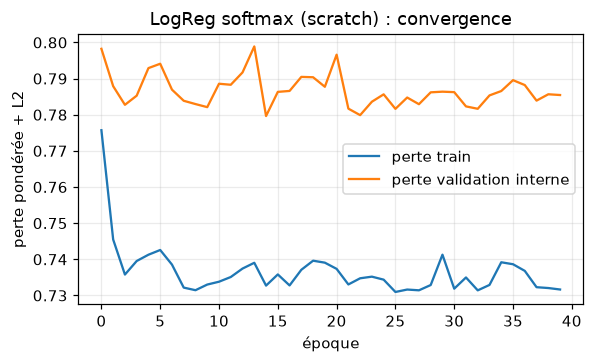

Arrêt à l'époque 40


In [30]:
demo = SoftmaxRegressionScratch(lam=1e-4, class_weight="balanced", epochs=300, patience=25).fit(Xtr_demo, y_train)
h = np.array(demo.history_)
plt.figure(figsize=(5.5, 3.4)); plt.plot(h[:, 0], label="perte train"); plt.plot(h[:, 1], label="perte validation interne")
plt.xlabel("époque"); plt.ylabel("perte pondérée + L2"); plt.legend(); plt.title("LogReg softmax (scratch) : convergence")
plt.tight_layout(); plt.savefig(FIG_DIR / "p2_logreg_learning_curve.png", dpi=150); plt.show()
print("Arrêt à l'époque", len(h))

## 6. SVM linéaire écrit à la main : Pegasos One-vs-Rest
**Fonction personnalisée** — *Réf. [3] Cortes & Vapnik (1995) pour le SVM ; [4] Shalev-Shwartz et al. (2011) pour l'algorithme **Pegasos** ; [12] Hsu & Lin (2002) pour le choix One-vs-Rest en multiclasse ; [17] Polyak & Juditsky (1992) pour le moyennage d'itérés.*

**Problème primal** (un classifieur par classe contre les autres) :
`min_w (λ/2)‖w‖² + (1/n) Σᵢ cᵢ·ℓ(yᵢ wᵀxᵢ)` avec `yᵢ ∈ {−1,+1}`, `cᵢ` = poids de la classe de l'exemple et `ℓ(m) = max(0, 1 − m)` (**hinge**, version d'origine) ou `ℓ(m) = max(0, 1 − m)²` (**hinge au carré**, la perte par défaut de `LinearSVC`, dérivable).

**Pegasos** [4] : à l'itération `t`, pas `ηₜ = 1/(λt)`, sous-gradient sur un mini-batch `B` :
`w ← w − ηₜ(λw − (1/|B|) Σ_{i∈B, marge<1} cᵢ yᵢ xᵢ)`, puis **projection** sur la boule de rayon `R = √(max c / λ)` (la solution optimale y appartient).

**Améliorations par rapport au SVM standard** :
- **poids de classes** dans la perte (SVM sensible au coût, pour `Enrolled`) ;
- option **hinge au carré** (non prévue dans l'algorithme d'origine, mais même schéma de sous-gradient : le gradient devient `−2(1−m)·y·x` sur les violations) pour la comparer à la hinge classique ;
- **moyennage** des itérés sur la seconde moitié de l'optimisation, qui stabilise la solution [4][17] ;
- biais traité par une colonne constante.

Le SVM linéaire sert de point de comparaison direct avec la régression logistique (mêmes variables, frontière linéaire dans les deux cas) : seule la **fonction de perte** diffère (hinge vs log-loss).

In [31]:
class PegasosLinearSVM:
    def __init__(self, lam=1e-3, class_weight=None, epochs=40, batch_size=64, average=True,
                 loss="hinge", random_state=SEED):
        self.lam, self.class_weight, self.epochs, self.loss = lam, class_weight, epochs, loss
        self.batch_size, self.average, self.random_state = batch_size, average, random_state

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        Xb = np.hstack([X, np.ones((len(X), 1))])
        sw = resolve_class_weight(self.class_weight, y)[y]
        R = np.sqrt((1 if self.loss == "hinge" else 2) * sw.max() / self.lam)   # rayon de la boule de projection
        n = len(y); total = self.epochs * int(np.ceil(n / self.batch_size))
        W = np.zeros((Xb.shape[1], K)); Wavg = np.zeros_like(W); navg = 0; t = 0
        for _ in range(self.epochs):
            perm = rng.permutation(n)
            for s in range(0, n, self.batch_size):
                b = perm[s:s + self.batch_size]; t += 1
                Yb = np.where(y[b][:, None] == np.arange(K), 1.0, -1.0)      # +1 pour la classe, -1 pour le reste
                margin = Yb * (Xb[b] @ W)
                active = (margin < 1) * sw[b][:, None]                         # exemples qui violent la marge, pondérés
                coef = active * Yb if self.loss == "hinge" else 2 * (1 - margin) * active * Yb
                grad = self.lam * W - Xb[b].T @ coef / len(b)
                W = W - grad / (self.lam * t)                                  # pas η_t = 1/(λ t)
                W *= np.minimum(1.0, R / np.maximum(np.linalg.norm(W, axis=0), 1e-12))   # projection
                if self.average and t > total / 2:
                    navg += 1; Wavg += (W - Wavg) / navg                       # moyenne courante des itérés
        self.W_ = Wavg if (self.average and navg > 0) else W
        return self

    def decision_function(self, X): return np.hstack([X, np.ones((len(X), 1))]) @ self.W_
    def predict(self, X):           return self.decision_function(X).argmax(axis=1)

### 6.1 Vérification : notre Pegasos vs `LinearSVC`
Même objectif régularisé (`C = 1/(λ·n)`), deux pertes : **hinge** (`LinearSVC(loss="hinge")`) et **hinge au carré** (`LinearSVC` par défaut). Pour chacune on compare la **valeur de l'objectif** atteinte par notre solveur et par liblinear (elles doivent être très proches) et l'accord des prédictions sur le train. C'est la preuve que notre Pegasos résout bien le bon problème.

In [32]:
def svm_objective(W, Xb, y, lam, loss, class_weight=None):
    sw = resolve_class_weight(class_weight, y)[y]; Yb = np.where(y[:, None] == np.arange(K), 1.0, -1.0)
    m = np.maximum(0, 1 - Yb * (Xb @ W)); m = m if loss == "hinge" else m ** 2
    return sum(0.5 * lam * (W[:, k] ** 2).sum() + (sw * m[:, k]).mean() for k in range(K))

Xb_demo = np.hstack([Xtr_demo, np.ones((len(Xtr_demo), 1))]); lam0 = 1e-3
rows = []
for loss in ("hinge", "squared_hinge"):
    peg = PegasosLinearSVM(lam=lam0, loss=loss, epochs=150).fit(Xtr_demo, y_train)
    lsv = LinearSVC(C=1 / (lam0 * len(y_train)), loss=loss, max_iter=200000).fit(Xtr_demo, y_train)
    W_l = np.vstack([lsv.coef_.T, lsv.intercept_])
    rows.append({"perte": loss, "objectif Pegasos": svm_objective(peg.W_, Xb_demo, y_train, lam0, loss),
                 "objectif LinearSVC": svm_objective(W_l, Xb_demo, y_train, lam0, loss),
                 "accord prédictions": (peg.predict(Xtr_demo) == lsv.predict(Xtr_demo)).mean(),
                 "F1 macro train Pegasos": f1_macro(y_train, peg.predict(Xtr_demo)),
                 "F1 macro train LinearSVC": f1_macro(y_train, lsv.predict(Xtr_demo))})
pd.DataFrame(rows).set_index("perte").round(4)

,objectif Pegasos,objectif LinearSVC,accord prédictions,F1 macro train Pegasos,F1 macro train LinearSVC
perte,,,,,
hinge,1.1130,1.1064,0.9619,0.5371,0.5326
squared_hinge,1.5041,1.5040,0.9994,0.5761,0.5765


**Lecture :** des objectifs presque égaux confirment que l'implémentation est correcte. Un écart de F1 entre les deux pertes n'est **pas** un défaut de notre code : c'est l'effet de la perte elle-même (hinge vs hinge au carré), que nous évaluons dans les expériences d'amélioration (§ 7.3).

### 6.2 SVM non linéaire : Random Fourier Features + Pegasos
**Fonction personnalisée** — *Réf. [5] Rahimi & Recht (2007).*

Le noyau RBF `k(x,x') = exp(−γ‖x−x'‖²)` est approché par une projection aléatoire explicite : `z(x) = √(2/D)·cos(Wᵀx + b)` avec `W ~ N(0, 2γI)` et `b ~ U[0, 2π]`, de sorte que `z(x)ᵀz(x') ≈ k(x,x')`. On entraîne ensuite notre SVM **linéaire** (Pegasos) dans cet espace. Intérêt : un SVM à frontière non linéaire **entièrement codé à la main**, de coût linéaire en `n` (le SVM à noyau exact coûte entre O(n²) et O(n³)), à comparer au `SVC(kernel="rbf")` standard.

In [33]:
class RFFPegasosSVM:
    def __init__(self, gamma=0.1, n_components=300, lam=1e-3, class_weight=None, epochs=40,
                 batch_size=64, average=True, loss="hinge", random_state=SEED):
        self.gamma, self.n_components, self.lam = gamma, n_components, lam
        self.class_weight, self.epochs, self.batch_size = class_weight, epochs, batch_size
        self.average, self.loss, self.random_state = average, loss, random_state

    def _z(self, X):
        return np.sqrt(2.0 / self.n_components) * np.cos(X @ self.Wr_ + self.br_)

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        self.Wr_ = rng.normal(0.0, np.sqrt(2 * self.gamma), size=(X.shape[1], self.n_components))
        self.br_ = rng.uniform(0, 2 * np.pi, size=self.n_components)
        self.svm_ = PegasosLinearSVM(self.lam, self.class_weight, self.epochs, self.batch_size,
                                     self.average, self.loss, self.random_state).fit(self._z(X), y)
        return self

    def decision_function(self, X): return self.svm_.decision_function(self._z(X))
    def predict(self, X):           return self.decision_function(X).argmax(axis=1)

# Vérification : erreur d'approximation du noyau RBF, qui doit diminuer quand D augmente
sub = Xtr_demo[:200]; g = 0.1
D2 = ((sub[:, None, :] - sub[None, :, :]) ** 2).sum(-1); K_exact = np.exp(-g * D2)
for D in (50, 200, 1000, 5000):
    r = RFFPegasosSVM(gamma=g, n_components=D); r.Wr_ = np.random.default_rng(0).normal(0, np.sqrt(2 * g), (sub.shape[1], D))
    r.br_ = np.random.default_rng(1).uniform(0, 2 * np.pi, D); Z = r._z(sub)
    print(f"D = {D:5d}  erreur absolue moyenne sur le noyau : {np.abs(Z @ Z.T - K_exact).mean():.4f}")

D =    50  erreur absolue moyenne sur le noyau : 0.0962
D =   200  erreur absolue moyenne sur le noyau : 0.0365
D =  1000  erreur absolue moyenne sur le noyau : 0.0177
D =  5000  erreur absolue moyenne sur le noyau : 0.0083


## 7. Réglage des hyperparamètres par validation croisée (sur le train uniquement)
**Fonction personnalisée** — *Réf. [15] Varma & Simon (2006) : choisir les réglages avec le jeu de test biaise l'estimation de l'erreur ; [14] Pedregosa et al. (2011) pour les modèles de référence.*

- Validation croisée **stratifiée à 5 plis** (`random_state=42`), score = **F1 macro**.
- Le préprocesseur (`StandardScaler`, regroupement des catégories rares) est **ré-appris dans chaque pli** sur la partie apprentissage du pli : aucune statistique de validation ne fuite dans l'entraînement.
- **Réserve sur les scores CV** : `FEATURES` provient de la sélection P1, effectuée une fois sur tout `X_train`. Les plis de validation P2 ont donc contribué indirectement au choix des variables. Les scores CV P2 sont conditionnels à cette sélection et peuvent être optimistes ; une évaluation entièrement imbriquée devrait refaire la sélection P1 dans chaque pli.
- Les plis sont préparés **une fois** et partagés par tous les modèles : tous sont comparés sur exactement les mêmes découpages.
- Le jeu de test n'est **pas** touché dans cette section.

In [34]:
def prepare_folds(X, y, features, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    folds = []
    for tr, va in skf.split(X, y):
        prep = make_prep(features)
        Xa = prep.fit_transform(X.iloc[tr][features])                # ajusté sur le pli d'apprentissage seulement
        Xv = prep.transform(X.iloc[va][features])
        folds.append((Xa, y[tr], Xv, y[va]))
    return folds

def cv_eval(make_model, folds):
    sc = []
    for Xa, ya, Xv, yv in folds:
        sc.append(f1_macro(yv, make_model().fit(Xa, ya).predict(Xv)))
    return float(np.mean(sc)), float(np.std(sc))

def grid_search(factory, grid, folds):
    rows = []
    for vals in itertools.product(*grid.values()):
        params = dict(zip(grid.keys(), vals))
        mean, std = cv_eval(lambda: factory(**params), folds)
        rows.append({"params": params, "f1_macro_cv": mean, "std": std})
    return pd.DataFrame(rows).sort_values("f1_macro_cv", ascending=False).reset_index(drop=True)

folds = prepare_folds(X_train, y_train, FEATURES)
print("Plis prêts :", len(folds), "| dimension après encodage :", folds[0][0].shape[1])

Plis prêts : 5 | dimension après encodage : 20


### 7.1 Modèles de référence (réglages par défaut, sans pondération)
Ce sont les **variantes standards** auxquelles nous comparerons nos améliorations. Leur F1 macro en validation croisée sert de point de départ.

In [35]:
baselines = {
    "LogReg sklearn (défaut)":   lambda: LogisticRegression(max_iter=2000, random_state=SEED),
    "LinearSVC sklearn (défaut)": lambda: LinearSVC(max_iter=20000, random_state=SEED),
    "SVC RBF sklearn (défaut)":  lambda: SVC(kernel="rbf", random_state=SEED),
}
cv_scores = {}
for name, mk in baselines.items():
    cv_scores[name] = cv_eval(mk, folds)
pd.DataFrame(cv_scores, index=["F1 macro CV (moy)", "écart-type"]).T.round(4)

,F1 macro CV (moy),écart-type
LogReg sklearn (défaut),0.6227,0.0166
LinearSVC sklearn (défaut),0.5790,0.0238
SVC RBF sklearn (défaut),0.6723,0.0103


### 7.2 Recherche en grille — régression logistique et SVM
Grilles volontairement modestes (lisibles et reproductibles) :
- **LogReg** : force de régularisation (`C` ou `λ`) × pondération des classes (`None` / `balanced`) ;
- **SVM linéaire** : `C` ou `λ` × pondération (× perte hinge / hinge au carré pour notre Pegasos) ;
- **SVM RBF** : `C` × `γ` × pondération ; **RFF-SVM** : `γ` × `λ` × pondération.

Le meilleur jeu de paramètres est celui qui maximise le **F1 macro moyen en validation croisée** (jamais le score de test).

In [36]:
mk_lr_sk   = lambda C, class_weight: LogisticRegression(C=C, class_weight=class_weight, max_iter=3000, random_state=SEED)
mk_lr_sc   = lambda lam, class_weight: SoftmaxRegressionScratch(lam=lam, class_weight=class_weight)
mk_lsvc    = lambda C, class_weight: LinearSVC(C=C, class_weight=class_weight, max_iter=20000, random_state=SEED)
mk_peg     = lambda lam, class_weight, loss: PegasosLinearSVM(lam=lam, class_weight=class_weight, loss=loss)
mk_svc     = lambda C, gamma, class_weight: SVC(kernel="rbf", C=C, gamma=gamma, class_weight=class_weight, random_state=SEED)
mk_rff     = lambda gamma, lam, class_weight, loss: RFFPegasosSVM(gamma=gamma, lam=lam, class_weight=class_weight, loss=loss)

CW = [None, "balanced"]
LOSSES = ["hinge", "squared_hinge"]
grids = {
    "LogReg sklearn (réglée)":    (mk_lr_sk, {"C": [0.01, 0.1, 1, 10, 100], "class_weight": CW}),
    "LogReg scratch (réglée)":    (mk_lr_sc, {"lam": [1e-4, 1e-3, 1e-2, 1e-1], "class_weight": CW}),
    "LinearSVC sklearn (réglé)":  (mk_lsvc,  {"C": [0.01, 0.1, 1, 10], "class_weight": CW}),
    "SVM Pegasos scratch (réglé)": (mk_peg,  {"lam": [1e-4, 1e-3, 1e-2], "class_weight": CW, "loss": LOSSES}),
    "SVC RBF sklearn (réglé)":    (mk_svc,   {"C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1], "class_weight": CW}),
    "SVM RFF scratch (réglé)":    (mk_rff,   {"gamma": [0.01, 0.05, 0.2], "lam": [1e-3, 1e-2], "class_weight": CW, "loss": LOSSES}),
}
search, best_params = {}, {}
for name, (factory, grid) in grids.items():
    res = grid_search(factory, grid, folds)
    search[name], best_params[name] = res, res.loc[0, "params"]
    cv_scores[name] = (res.loc[0, "f1_macro_cv"], res.loc[0, "std"])
    print(f"{name:30s} CV F1 macro = {res.loc[0, 'f1_macro_cv']:.4f} ± {res.loc[0, 'std']:.4f}   {best_params[name]}")

LogReg sklearn (réglée)        CV F1 macro = 0.6858 ± 0.0168   {'C': 0.1, 'class_weight': 'balanced'}
LogReg scratch (réglée)        CV F1 macro = 0.6846 ± 0.0195   {'lam': 0.001, 'class_weight': 'balanced'}
LinearSVC sklearn (réglé)      CV F1 macro = 0.6463 ± 0.0131   {'C': 10, 'class_weight': 'balanced'}
SVM Pegasos scratch (réglé)    CV F1 macro = 0.6678 ± 0.0134   {'lam': 0.01, 'class_weight': 'balanced', 'loss': 'squared_hinge'}
SVC RBF sklearn (réglé)        CV F1 macro = 0.6927 ± 0.0170   {'C': 10, 'gamma': 0.1, 'class_weight': 'balanced'}
SVM RFF scratch (réglé)        CV F1 macro = 0.6879 ± 0.0191   {'gamma': 0.2, 'lam': 0.001, 'class_weight': 'balanced', 'loss': 'squared_hinge'}


**Détail des 5 meilleures configurations de chaque modèle** (pour le rapport : montre la sensibilité aux hyperparamètres).

In [37]:
for name, res in search.items():
    print("\n" + name)
    print(res.head(5).assign(params=lambda d: d.params.astype(str)).round(4).to_string(index=False))


LogReg sklearn (réglée)
                                 params  f1_macro_cv    std
 {'C': 0.1, 'class_weight': 'balanced'}       0.6858 0.0168
   {'C': 1, 'class_weight': 'balanced'}       0.6836 0.0138
  {'C': 10, 'class_weight': 'balanced'}       0.6827 0.0110
 {'C': 100, 'class_weight': 'balanced'}       0.6826 0.0115
{'C': 0.01, 'class_weight': 'balanced'}       0.6768 0.0174

LogReg scratch (réglée)
                                     params  f1_macro_cv    std
 {'lam': 0.001, 'class_weight': 'balanced'}       0.6846 0.0195
{'lam': 0.0001, 'class_weight': 'balanced'}       0.6800 0.0125
  {'lam': 0.01, 'class_weight': 'balanced'}       0.6798 0.0254
   {'lam': 0.1, 'class_weight': 'balanced'}       0.6507 0.0311
      {'lam': 0.0001, 'class_weight': None}       0.6171 0.0188

LinearSVC sklearn (réglé)
                                 params  f1_macro_cv    std
  {'C': 10, 'class_weight': 'balanced'}       0.6463 0.0131
   {'C': 1, 'class_weight': 'balanced'}       0.6456 0.0138

### 7.3 Améliorations vs variantes standards (ablation des améliorations)
On mesure, en validation croisée sur les mêmes plis, l'apport de chaque composant ajouté (`λ` fixé à 1e-3) :

| Modèle | Version de base | + amélioration(s) |
|---|---|---|
| LogReg scratch | descente de gradient simple | + Adam → + poids balanced → + arrêt précoce |
| SVM Pegasos | sans poids, sans moyennage, perte hinge | + moyennage → + poids balanced → perte hinge au carré |

In [38]:
variants = {
    "LogReg scratch — GD simple":                    lambda: SoftmaxRegressionScratch(lam=1e-3, optimizer="gd", lr=0.5, early_stopping=False, epochs=200),
    "LogReg scratch — + Adam":                       lambda: SoftmaxRegressionScratch(lam=1e-3, early_stopping=False),
    "LogReg scratch — + Adam + balanced":            lambda: SoftmaxRegressionScratch(lam=1e-3, class_weight="balanced", early_stopping=False),
    "LogReg scratch — + Adam + balanced + arrêt précoce": lambda: SoftmaxRegressionScratch(lam=1e-3, class_weight="balanced", early_stopping=True),
    "Pegasos — de base (sans moyennage, sans poids)": lambda: PegasosLinearSVM(lam=1e-3, average=False),
    "Pegasos — + moyennage":                         lambda: PegasosLinearSVM(lam=1e-3, average=True),
    "Pegasos — + moyennage + balanced":              lambda: PegasosLinearSVM(lam=1e-3, average=True, class_weight="balanced"),
    "Pegasos — hinge au carré (+ moyennage)":        lambda: PegasosLinearSVM(lam=1e-3, loss="squared_hinge"),
    "Pegasos — hinge au carré + balanced":           lambda: PegasosLinearSVM(lam=1e-3, loss="squared_hinge", class_weight="balanced"),
}
rows = []
for name, mk in variants.items():
    m, s = cv_eval(mk, folds); rows.append({"variante": name, "F1 macro CV": m, "écart-type": s})
variants_df = pd.DataFrame(rows).round(4); variants_df

,variante,F1 macro CV,écart-type
0,LogReg scratch — GD simple,0.6153,0.0132
1,LogReg scratch — + Adam,0.6322,0.0344
2,LogReg scratch — + Adam + balanced,0.6738,0.0154
3,LogReg scratch — + Adam + balanced + arrêt pré...,0.6846,0.0195
4,"Pegasos — de base (sans moyennage, sans poids)",0.5507,0.0209
5,Pegasos — + moyennage,0.5389,0.0099
6,Pegasos — + moyennage + balanced,0.6597,0.0070
7,Pegasos — hinge au carré (+ moyennage),0.5753,0.0238
8,Pegasos — hinge au carré + balanced,0.6401,0.0050


**Interprétation.**

Quelle amélioration apporte réellement du F1 macro ? la pondération améliore-t-elle surtout `Enrolled` (F1 par classe, § 8) au prix d'un recul sur `Graduate` ? le moyennage stabilise-t-il Pegasos (écart-type plus faible) ?


*Régression logistique (scratch).* Chaque ajout améliore le F1 macro moyen en validation croisée : 0,615 (descente de gradient simple) → 0,632 (+ Adam) → 0,674 (+ poids `balanced`) → 0,685 (+ arrêt précoce). L'amélioration qui compte le plus est la **pondération des classes** (+0,042). Le gain d'Adam (+0,017) est à nuancer : l'écart-type passe de 0,013 à 0,034, donc il n'est pas établi avec certitude. L'arrêt précoce apporte un gain modeste (+0,011) avec une variabilité comparable.

*Effet de la pondération sur les classes (voir § 8).* Sur le test, la pondération fait passer le F1 de `Enrolled` de 0,204 à 0,410 pour la régression logistique de scikit-learn, mais l'accuracy baisse de 0,727 à 0,695 et le F1 de `Graduate` de 0,839 à 0,801. Le F1 macro monte parce qu'on accepte de perdre un peu sur la classe majoritaire pour mieux détecter la classe minoritaire : c'est un compromis, pas un gain sur toutes les classes.

*SVM Pegasos.* Le **moyennage** n'améliore pas le F1 macro moyen (0,551 → 0,539), mais il stabilise l'optimisation : l'écart-type entre plis passe de 0,021 à 0,010. La pondération `balanced` est de loin l'amélioration la plus efficace (0,539 → 0,660). La perte hinge au carré est meilleure que la hinge seule (0,575 contre 0,539), mais devient moins bonne une fois les poids ajoutés (0,640 contre 0,660).

*Conclusion.* Une amélioration utile isolément n'est pas forcément cumulative, et une amélioration sans gain de score (le moyennage) peut quand même avoir un intérêt (la stabilité). La pondération des classes est la modification la plus rentable pour les deux modèles.

## 8. Évaluation finale sur le jeu de test (une seule fois par modèle)
Le préprocesseur est appris sur **tout le train**, puis appliqué au test. Chaque modèle (références **et** versions réglées) est entraîné sur le train complet, et **prédit le test une seule fois** ; prédictions et scores sont conservés, et toutes les analyses suivantes (tableaux, matrices de confusion, ROC, bootstrap) réutilisent ces sorties sans jamais ré-interroger le test. Les modèles et hyperparamètres sont fixés avant cette évaluation ; les scores du test sont descriptifs et ne doivent pas servir à retoucher ou sélectionner un modèle après coup.

Pour les courbes ROC, un score continu par classe est nécessaire : **probabilités** pour la régression logistique, **marges** (`decision_function`) pour les SVM. Le test évalue les modèles préspécifiés ; il ne sert ni à ajuster leurs paramètres ni à choisir un modèle après observation des résultats.

In [39]:
prep_full = make_prep(FEATURES)
Xtr_full = prep_full.fit_transform(X_train[FEATURES])
Xte = prep_full.transform(X_test[FEATURES])

def get_scores(model, X):
    if hasattr(model, "predict_proba"):      return model.predict_proba(X)
    return model.decision_function(X)

final_models = {**baselines}
for name, (factory, _) in grids.items():
    p = best_params[name]; final_models[name] = (lambda f=factory, p=p: f(**p))

results = {}
for name, mk in final_models.items():
    model = mk().fit(Xtr_full, y_train)
    results[name] = {"pred": model.predict(Xte), "scores": get_scores(model, Xte), "model": model}

rows = []
for name, r in results.items():
    s = summarize(y_test, r["pred"]); _, macro_auc = roc_ovr(y_test, r["scores"])
    rows.append({"modèle": name, "F1 macro CV": cv_scores[name][0], "F1 macro TEST": s["f1_macro"],
                 "F1 weighted": s["f1_weighted"], "accuracy": s["accuracy"], "acc. équilibrée": s["balanced_acc"],
                 **{f"F1 {c}": s[f"f1_{c}"] for c in CLASSES}, "AUC macro (OvR)": macro_auc})
results_df = pd.DataFrame(rows).set_index("modèle").round(4)
results_df

,F1 macro CV,F1 macro TEST,F1 weighted,accuracy,acc. équilibrée,F1 Dropout,F1 Enrolled,F1 Graduate,AUC macro (OvR)
modèle,,,,,,,,,
LogReg sklearn (défaut),0.6227,0.5917,0.6906,0.7266,0.6034,0.7323,0.2037,0.8390,0.8534
LinearSVC sklearn (défaut),0.5790,0.5632,0.6782,0.7356,0.5953,0.7470,0.1011,0.8415,0.8308
SVC RBF sklearn (défaut),0.6723,0.6584,0.7311,0.7480,0.6483,0.7413,0.3849,0.8490,0.8335
LogReg sklearn (réglée),0.6858,0.6458,0.7069,0.6949,0.6506,0.7263,0.4096,0.8014,0.8489
LogReg scratch (réglée),0.6846,0.6355,0.6996,0.6893,0.6404,0.7215,0.3867,0.7981,0.8434
LinearSVC sklearn (réglé),0.6463,0.6099,0.6994,0.7209,0.6152,0.7205,0.2683,0.8409,0.8305
SVM Pegasos scratch (réglé),0.6678,0.6147,0.6915,0.6915,0.6152,0.7086,0.3218,0.8136,0.8245
SVC RBF sklearn (réglé),0.6927,0.6541,0.7125,0.6949,0.6640,0.7113,0.4396,0.8115,0.8438
SVM RFF scratch (réglé),0.6879,0.6649,0.7198,0.7062,0.6741,0.7200,0.4623,0.8123,0.8616


**Moyenne utilisée pour le F1** : *macro* (moyenne non pondérée des 3 F1) comme critère principal, *weighted* et *par classe* en complément [10]. Comparer la colonne « CV » et la colonne « TEST » permet de repérer un éventuel sur-ajustement de la sélection d'hyperparamètres.

### 8.1 Matrices de confusion
Normalisées par ligne (chaque ligne = 100 % des étudiants réels de la classe, donc la diagonale est le **rappel**) avec les effectifs bruts entre parenthèses. Elles montrent *où* chaque modèle se trompe ; typiquement `Enrolled` est la classe la plus confondue.

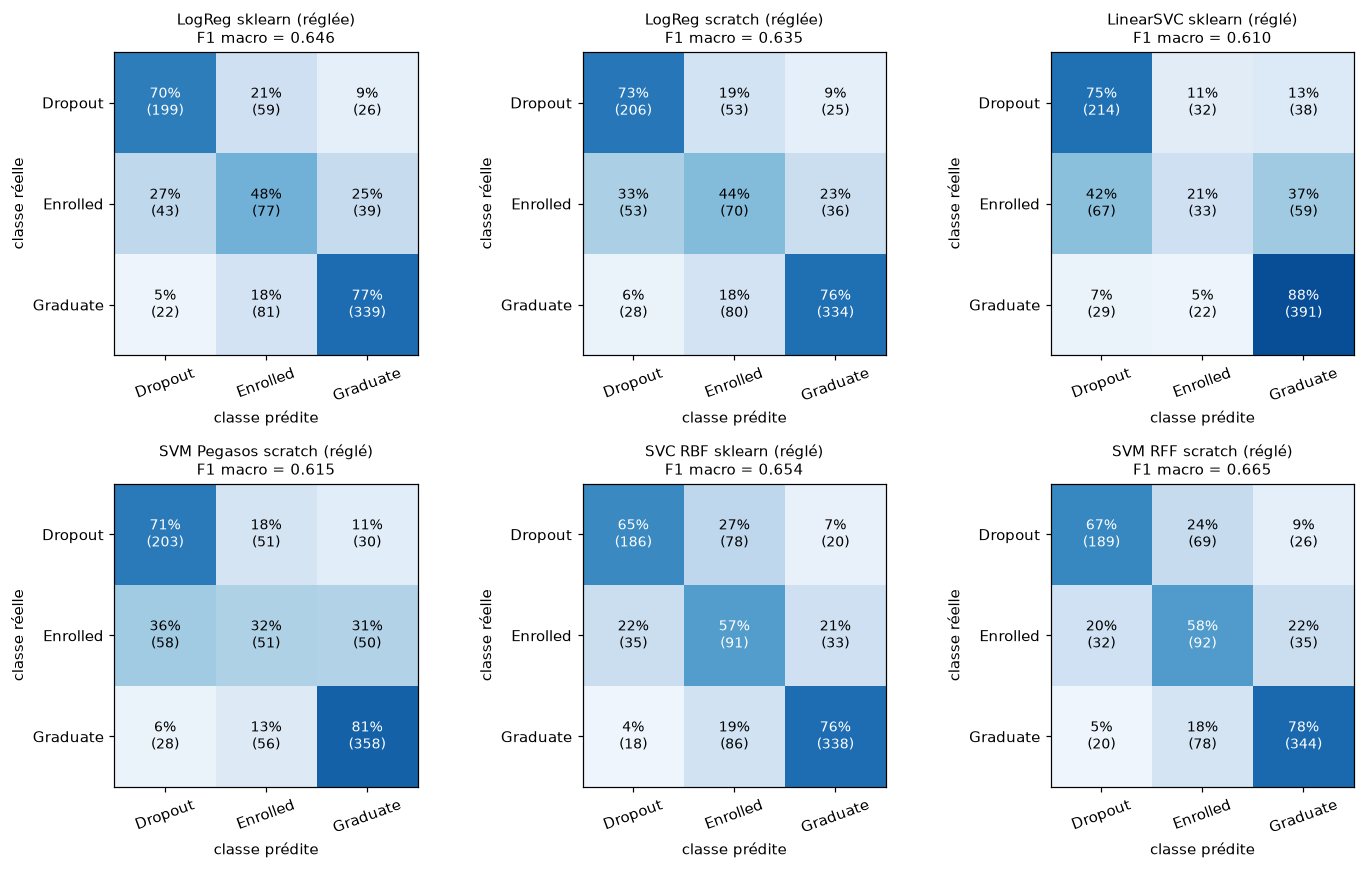

In [40]:
tuned = [n for n in results if "réglé" in n]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, name in zip(axes.ravel(), tuned):
    cm = confusion_matrix_np(y_test, results[name]["pred"]); cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center",
                    color="white" if cmn[i, j] > .5 else "black", fontsize=9)
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=20); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES)
    ax.set_title(f"{name}\nF1 macro = {f1_macro(y_test, results[name]['pred']):.3f}", fontsize=10)
    ax.set_xlabel("classe prédite"); ax.set_ylabel("classe réelle")
plt.tight_layout(); plt.savefig(FIG_DIR / "p2_confusion_matrices.png", dpi=150); plt.show()

### 8.2 Courbes ROC One-vs-Rest
Une courbe par classe (« cette classe contre les deux autres »), pour les quatre modèles centraux : régression logistique (sklearn et scratch) et SVM (RBF sklearn et Pegasos scratch). Une AUC de 0,5 correspond au hasard, 1 à une séparation parfaite [9]. Les AUC de **tous** les modèles figurent dans le tableau ci-dessous.

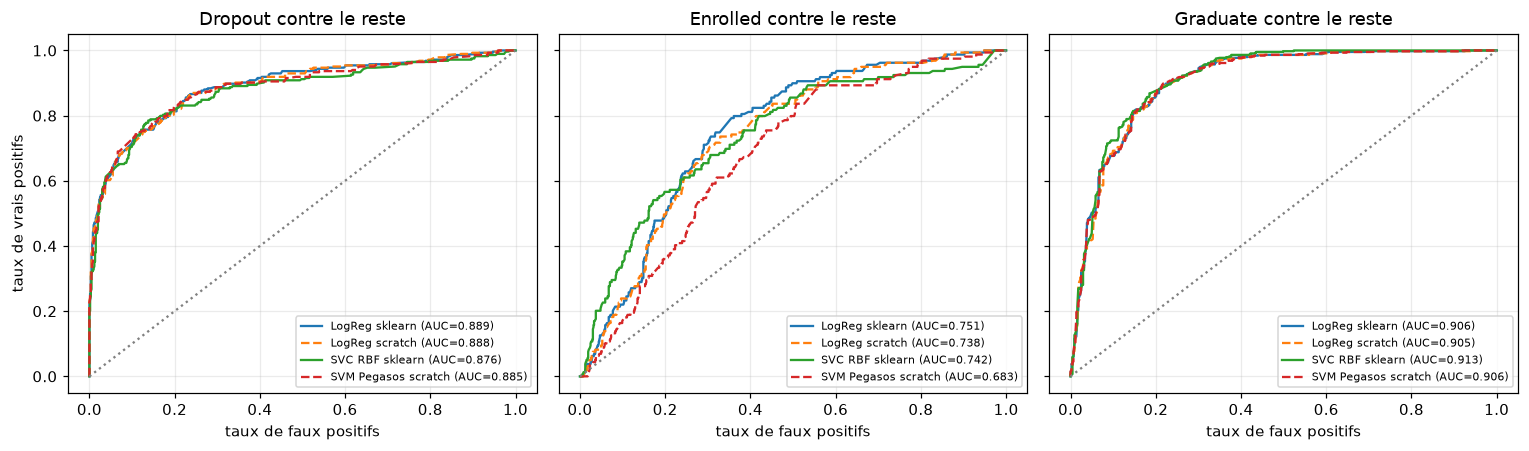

,AUC Dropout,AUC Enrolled,AUC Graduate,AUC macro
modèle,,,,
LogReg sklearn (défaut),0.8912,0.7620,0.9069,0.8534
LinearSVC sklearn (défaut),0.8883,0.6969,0.9071,0.8308
SVC RBF sklearn (défaut),0.8666,0.7390,0.8949,0.8335
LogReg sklearn (réglée),0.8893,0.7509,0.9063,0.8489
LogReg scratch (réglée),0.8879,0.7375,0.9047,0.8434
LinearSVC sklearn (réglé),0.8884,0.6969,0.9064,0.8305
SVM Pegasos scratch (réglé),0.8848,0.6832,0.9056,0.8245
SVC RBF sklearn (réglé),0.8764,0.7422,0.9129,0.8438
SVM RFF scratch (réglé),0.8823,0.7865,0.9162,0.8616


In [41]:
roc_models = ["LogReg sklearn (réglée)", "LogReg scratch (réglée)", "SVC RBF sklearn (réglé)", "SVM Pegasos scratch (réglé)"]
styles = ["-", "--", "-", "--"]
fig, axes = plt.subplots(1, K, figsize=(14, 4.2), sharey=True)
for k, cname in enumerate(CLASSES):
    for name, ls in zip(roc_models, styles):
        curves, _ = roc_ovr(y_test, results[name]["scores"]); fpr, tpr, a = curves[cname]
        axes[k].plot(fpr, tpr, ls, label=f"{name.split(' (')[0]} (AUC={a:.3f})")
    axes[k].plot([0, 1], [0, 1], ":", color="grey"); axes[k].set_title(f"{cname} contre le reste")
    axes[k].set_xlabel("taux de faux positifs"); axes[k].legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("taux de vrais positifs")
plt.tight_layout(); plt.savefig(FIG_DIR / "p2_roc_ovr.png", dpi=150); plt.show()

auc_rows = []
for name, r in results.items():
    curves, macro = roc_ovr(y_test, r["scores"])
    auc_rows.append({"modèle": name, **{f"AUC {c}": curves[c][2] for c in CLASSES}, "AUC macro": macro})
pd.DataFrame(auc_rows).set_index("modèle").round(4)

### 8.3 Incertitude : intervalles de confiance bootstrap
**Fonction personnalisée** — *Réf. [13] Efron & Tibshirani (1993).*

Un écart de 0,01 de F1 est-il réel ou dû au hasard du découpage ? On rééchantillonne **1 000 fois** le jeu de test (avec remise) et on recalcule le F1 macro à partir des prédictions **déjà obtenues**, sans réentraîner ni retoucher les modèles. On calcule aussi la **différence appariée** entre paires de modèles **déclarées à l'avance** (par rapport à nos questions de recherche, pas choisies après coup) : si l'intervalle à 95 % de la différence contient 0, on ne peut pas conclure à une supériorité.

In [42]:
B = 1000
rb = np.random.default_rng(SEED)
boot_idx = rb.integers(0, len(y_test), size=(B, len(y_test)))
boot_f1 = {name: np.array([f1_macro(y_test[i], r["pred"][i]) for i in boot_idx]) for name, r in results.items()}

ci = pd.DataFrame({name: {"F1 macro (test)": f1_macro(y_test, results[name]["pred"]),
                          "IC95% bas": np.percentile(v, 2.5), "IC95% haut": np.percentile(v, 97.5)}
                   for name, v in boot_f1.items()}).T.round(4)
display(ci)

pairs = [("LogReg sklearn (réglée)", "SVC RBF sklearn (réglé)"),            # standard vs standard
         ("LogReg scratch (réglée)", "SVM Pegasos scratch (réglé)"),         # perso vs perso (linéaire)
         ("LogReg scratch (réglée)", "SVM RFF scratch (réglé)"),             # LogReg vs SVM non linéaire perso
         ("LogReg sklearn (défaut)", "LogReg sklearn (réglée)"),             # effet du réglage + poids
         ("SVC RBF sklearn (défaut)", "SVC RBF sklearn (réglé)")]
rows = []
for a, b in pairs:
    d = boot_f1[b] - boot_f1[a]; lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({"A": a, "B": b, "F1(B) − F1(A)": d.mean(), "IC95% bas": lo, "IC95% haut": hi,
                 "différence significative": not (lo <= 0 <= hi)})
pd.DataFrame(rows).round(4)

,F1 macro (test),IC95% bas,IC95% haut
LogReg sklearn (défaut),0.5917,0.5609,0.6258
LinearSVC sklearn (défaut),0.5632,0.5357,0.5919
SVC RBF sklearn (défaut),0.6584,0.6256,0.6927
LogReg sklearn (réglée),0.6458,0.6142,0.6762
LogReg scratch (réglée),0.6355,0.6029,0.6646
LinearSVC sklearn (réglé),0.6099,0.5760,0.6458
SVM Pegasos scratch (réglé),0.6147,0.5807,0.6455
SVC RBF sklearn (réglé),0.6541,0.6229,0.6855
SVM RFF scratch (réglé),0.6649,0.6346,0.6951


,A,B,F1(B) − F1(A),IC95% bas,IC95% haut,différence significative
0,LogReg sklearn (réglée),SVC RBF sklearn (réglé),0.0084,-0.0096,0.0269,False
1,LogReg scratch (réglée),SVM Pegasos scratch (réglé),-0.0208,-0.0443,0.0019,False
2,LogReg scratch (réglée),SVM RFF scratch (réglé),0.0294,0.0080,0.0526,True
3,LogReg sklearn (défaut),LogReg sklearn (réglée),0.0535,0.0207,0.0870,True
4,SVC RBF sklearn (défaut),SVC RBF sklearn (réglé),-0.0047,-0.0359,0.0241,False


### 8.4 Interprétabilité de la régression logistique (scratch)
Les coefficients (variables standardisées) indiquent l'effet de chaque variable sur le score de chaque classe : un avantage de la régression logistique sur le SVM à noyau, qui est une « boîte noire ». À lire avec prudence quand des colonnes one-hot de `Course` sont corrélées.

In [43]:
Wc = results["LogReg scratch (réglée)"]["model"].W_[:-1]
coef = pd.DataFrame(Wc, index=prep_full.get_feature_names_out(), columns=CLASSES)
coef.loc[coef.abs().max(axis=1).sort_values(ascending=False).index].head(12).round(3)

,Dropout,Enrolled,Graduate
Curricular units 2nd sem (approved),-1.519,-0.274,1.702
Tuition fees up to date,-1.524,0.477,1.299
Curricular units 1st sem (evaluations),0.239,0.388,-0.993
Course_9853,0.705,0.061,-0.793
Course_171,-0.764,0.207,0.584
Course_9238,-0.398,-0.357,0.702
Course_9119,-0.022,0.679,-0.598
Course_9991,0.457,0.087,-0.583
Course_9085,-0.508,0.041,0.499
Course_9500,0.426,0.099,-0.427


## 9. Ablation : que valent les variables sélectionnées ? (validation croisée sur le train)
**Réf. [1][2]** : les auteurs du jeu de données montrent que les résultats académiques du 1ᵉʳ et du 2ᵉ semestre sont très informatifs, ce qui pose la question du **moment de la prédiction**.

Quatre jeux de variables comparés avec deux modèles de référence (réglage identique, pondération `balanced`) :
1. **Les 4 variables de P1** ;
2. **Les 4 sans `Course`** (pour mesurer le poids de la variable à 17 modalités) ;
3. **Toutes les variables** (jusqu'où va-t-on avec plus d'information ?) ;
4. **Toutes sauf `Curricular units*`** : *approximation* d'une prédiction **à l'inscription** (sans notes de semestre). Attention : quelques variables restantes (par ex. bourse, dettes, frais à jour) peuvent être observées après l'inscription, donc ce n'est qu'une approximation.

Uniquement en validation croisée sur le train : **le test n'est pas utilisé**. Réserve : pour les jeux 1 et 2, les variables retenues ont été sélectionnées par P1 sur tout `X_train` ; leurs scores CV ne sont donc pas une estimation entièrement indépendante de cette sélection.

In [44]:
feat_sets = {
    "1) 4 variables retenues par P1": FEATURES,
    "2) 4 variables sans Course":     [f for f in FEATURES if f != "Course"],
    "3) toutes les variables":         list(X_train.columns),
    "4) toutes sauf 'Curricular units*' (≈ inscription)": [c for c in X_train.columns if not c.startswith("Curricular units")],
}
ab_models = {"LogReg sklearn (C=1, balanced)": lambda: LogisticRegression(C=1, class_weight="balanced", max_iter=3000, random_state=SEED),
             "SVC RBF sklearn (C=1, balanced)": lambda: SVC(kernel="rbf", C=1, class_weight="balanced", random_state=SEED)}
rows = []
for fs_name, feats in feat_sets.items():
    fo = prepare_folds(X_train, y_train, feats)
    row = {"jeu de variables": fs_name, "nb colonnes": fo[0][0].shape[1]}
    for mn, mk in ab_models.items():
        m, s = cv_eval(mk, fo); row[mn] = f"{m:.4f} ± {s:.4f}"
    rows.append(row)
pd.DataFrame(rows).set_index("jeu de variables")

,nb colonnes,"LogReg sklearn (C=1, balanced)","SVC RBF sklearn (C=1, balanced)"
jeu de variables,,,
1) 4 variables retenues par P1,20,0.6836 ± 0.0138,0.6887 ± 0.0181
2) 4 variables sans Course,3,0.6645 ± 0.0225,0.6749 ± 0.0150
3) toutes les variables,116,0.7087 ± 0.0167,0.7158 ± 0.0181
4) toutes sauf 'Curricular units*' (≈ inscription),104,0.5695 ± 0.0187,0.5824 ± 0.0142


**Interprétation.**

*Faut-il plus que 4 variables ? (jeu 1 contre jeu 3).* Utiliser toutes les variables (116 colonnes) améliore le F1 macro de +0,025 pour la régression logistique (0,684 → 0,709) et de +0,027 pour le SVC RBF (0,689 → 0,716). Les 4 variables retenues par P1 conservent donc environ 96 % de la performance obtenue avec toutes les variables, avec 20 colonnes au lieu de 116. Le choix de k = 4 est un bon compromis entre simplicité et performance, mais il n'est pas sans coût : une partie de l'information utile est écartée. L'écart est du même ordre de grandeur que l'écart-type entre plis (0,014 à 0,023) ; il est cependant de même sens et de même taille pour les deux modèles, ce qui le rend crédible.

*`Course` est-elle utile ? (jeu 1 contre jeu 2).* Retirer `Course` fait baisser le F1 macro de 0,019 pour la régression logistique (0,684 → 0,665) et de 0,014 pour le SVC RBF (0,689 → 0,675). La variable est donc utile pour les deux modèles et non simplement « encombrante », malgré ses 17 modalités qui représentent 17 des 20 colonnes encodées. L'apport reste toutefois modeste, du même ordre qu'un écart-type entre plis, et doit être interprété avec prudence.

*Dépendance aux résultats des semestres (jeu 3 contre jeu 4).* Retirer les variables `Curricular units*` fait chuter le F1 macro d'environ 0,14 (0,709 → 0,570 pour la régression logistique, 0,716 → 0,582 pour le SVC RBF). Cet écart est bien supérieur à la variabilité entre plis : le modèle dépend fortement des résultats académiques des deux semestres. Il prédit donc le décrochage en fin de 2ᵉ semestre et ne peut pas être présenté comme un outil de repérage des étudiants à risque dès l'inscription. Le jeu 4 n'est qu'une approximation de ce scénario : quelques variables restantes (frais à jour, bourse, etc.) peuvent être observées après l'inscription.

*Limites de cette expérience.* Elle n'utilise que deux modèles de référence avec des réglages fixes (C = 1, `balanced`), n'est évaluée qu'en validation croisée sur le train, et ne distingue pas un effet réel d'un simple hasard de découpage pour des écarts inférieurs à 0,02.

## 10. Discussion : avantages et limites des deux familles de modèles

| | Régression logistique | SVM |
|---|---|---|
| **Principe** | Modèle probabiliste : sortie = probabilités par classe (à recalibrer si l'on pondère les classes) [7][8] | Maximise la marge ; sortie = score de marge, pas de probabilité native [3][7] |
| **Avantages** | Interprétable (coefficients), rapide, convexe, probabilités directement utilisables | Frontière non linéaire possible (noyau RBF), efficace en grande dimension, robuste grâce à la marge [3] |
| **Limites** | Frontière linéaire (sauf variables d'interaction), sensible à la colinéarité | Choix de `C` et `γ` sensibles ; sensible aux échelles ; noyau exact coûteux en O(n²–n³) ; moins lisible |
| **Déséquilibre des classes** | Pondération de la perte [11] | Pondération de la pénalité `C` par classe [11] |
| **Multiclasse** | Softmax natif | Décomposition One-vs-Rest (ou One-vs-One) [12] |

**Constats propres à ce jeu de données**

- **Meilleurs scores observés sur le test.** Les F1 macro sont proches : SVM RFF 0,665, SVC RBF réglé 0,654 (0,658 avec les réglages par défaut), régression logistique de scikit-learn réglée 0,646, notre régression logistique 0,636. Pour `Enrolled`, les meilleurs F1 sont ceux du SVM RFF (0,462) et du SVC RBF réglé (0,440), devant la régression logistique réglée (0,410). Ce classement décrit le test et ne doit pas servir à une sélection après coup.
- **Significativité.** Les intervalles bootstrap se chevauchent presque tous (largeur d'environ ±0,03). Régression logistique réglée et SVC RBF réglé sont statistiquement équivalents (différence +0,008, IC [−0,010 ; +0,027]). La différence entre notre SVM RFF et notre régression logistique scratch est +0,029, IC [+0,008 ; +0,053] ; avec cinq comparaisons sans correction, c'est un indice, pas une preuve.
- **Pondération des classes.** Pour la régression logistique de scikit-learn, elle fait passer le F1 de `Enrolled` de 0,204 à 0,410 et le F1 macro de 0,592 à 0,646 (différence significative), mais l'accuracy baisse de 0,727 à 0,695 et le F1 de `Graduate` de 0,839 à 0,801. C'est un compromis en faveur de la classe minoritaire.
- **Implémentations personnalisées.** Notre régression logistique atteint une perte de 0,6349 contre 0,6346 pour scikit-learn (98,9 % d'accord sur les prédictions) ; sur le test, son F1 macro est à 0,010 de celui de scikit-learn (0,636 contre 0,646). Notre Pegasos atteint le même objectif que `LinearSVC` (accord de 96,2 % en hinge, 99,9 % en hinge au carré). Le SVM RFF personnalisé (0,665) dépasse légèrement le SVC RBF réglé (0,654) sur ce test.
- **Noyau RBF contre SVM linéaire.** Les SVM non linéaires (SVC RBF 0,654 et SVM RFF 0,665) dépassent les SVM linéaires (LinearSVC 0,610 et Pegasos 0,615) d'environ 0,04 à 0,05 de F1 macro, surtout grâce à `Enrolled` (F1 de 0,44 à 0,46 contre 0,27 à 0,32 ; AUC de 0,74 à 0,79 contre 0,68 à 0,70). Ce gain n'a pas été testé par bootstrap pour ces paires précises. Avec seulement 4 variables, la régression logistique, pourtant linéaire, reste proche des SVM non linéaires.

**Limites** : 4 variables seulement (l'ablation montre un plafond d'environ 0,71 avec toutes les variables) ; `Course` encodée en one-hot (17 modalités) ; un seul jeu de test de 885 étudiants (d'où le bootstrap) ; les scores CV des modèles réglés peuvent être optimistes (sélection d'hyperparamètres [15] et sélection P1 des variables effectuée avant la CV P2) ; scénario « fin de 2ᵉ semestre », non applicable à un repérage dès l'inscription ; données d'un seul établissement portugais [1].

## Bibliographie

[1] Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting Student Dropout and Academic Success. *Data, 7*(11), Article 146. https://doi.org/10.3390/data7110146

[2] Martins, M. V., Tolledo, D., Machado, J., Baptista, L. M. T., & Realinho, V. (2021). Early prediction of student's performance in higher education: A case study. In *Trends and Applications in Information Systems and Technologies* (WorldCIST 2021), *Advances in Intelligent Systems and Computing* (Vol. 1365, pp. 166–175). Springer. https://doi.org/10.1007/978-3-030-72657-7_16

[3] Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*, 273–297. https://doi.org/10.1007/BF00994018

[4] Shalev-Shwartz, S., Singer, Y., Srebro, N., & Cotter, A. (2011). Pegasos: Primal estimated sub-gradient solver for SVM. *Mathematical Programming, 127*(1), 3–30. https://doi.org/10.1007/s10107-010-0420-4

[5] Rahimi, A., & Recht, B. (2007). Random features for large-scale kernel machines. In *Advances in Neural Information Processing Systems 20* (pp. 1177–1184). https://papers.nips.cc/paper_files/paper/2007/hash/013a006f03dbc5392effeb8f18fda755-Abstract.html

[6] Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980

[7] Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer. https://link.springer.com/book/9780387310732

[8] Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7

[9] Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters, 27*(8), 861–874. https://doi.org/10.1016/j.patrec.2005.10.010

[10] Sokolova, M., & Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management, 45*(4), 427–437. https://doi.org/10.1016/j.ipm.2009.03.002

[11] Japkowicz, N., & Stephen, S. (2002). The class imbalance problem: A systematic study. *Intelligent Data Analysis, 6*(5), 429–449. https://doi.org/10.3233/IDA-2002-6504

[12] Hsu, C.-W., & Lin, C.-J. (2002). A comparison of methods for multiclass support vector machines. *IEEE Transactions on Neural Networks, 13*(2), 415–425. https://doi.org/10.1109/72.991427

[13] Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.

[14] Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

[15] Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, Article 91. https://doi.org/10.1186/1471-2105-7-91

[16] Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634

[17] Polyak, B. T., & Juditsky, A. B. (1992). Acceleration of stochastic approximation by averaging. *SIAM Journal on Control and Optimization, 30*(4), 838–855. https://doi.org/10.1137/0330046

## Référence du jeu de données

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89. Licence : CC BY 4.0.